<a href="https://colab.research.google.com/github/Ravula-vigneshwar/machine-learning-projects/blob/main/student_dropout_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# !pip install gradio pandas scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [ ]:
df = pd.read_csv('student_dropout_extended_dataset.csv')


In [ ]:
print("Dataset Overview:")
print(df.info())

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Student_ID              3000 non-null   int64  
 1   Attendance_Percentage   3000 non-null   int64  
 2   Internal_Marks          3000 non-null   int64  
 3   Previous_Sem_GPA        3000 non-null   float64
 4   Assignments_Submitted   3000 non-null   int64  
 5   LMS_Activity_Score      3000 non-null   int64  
 6   Disciplinary_Issues     3000 non-null   int64  
 7   Family_Issues           3000 non-null   object 
 8   Family_Income_Level     3000 non-null   object 
 9   Parent_Occupation       3000 non-null   object 
 10  Health_Issues           3000 non-null   object 
 11  Financial_Stress_Level  3000 non-null   int64  
 12  Reason_For_Dropout      2695 non-null   object 
 13  Current_Status          3000 non-null   object 
 14  Dropout_Status        

/tmp/ipykernel_4263/292858691.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Dropout_Status', data=df, palette='Set2')


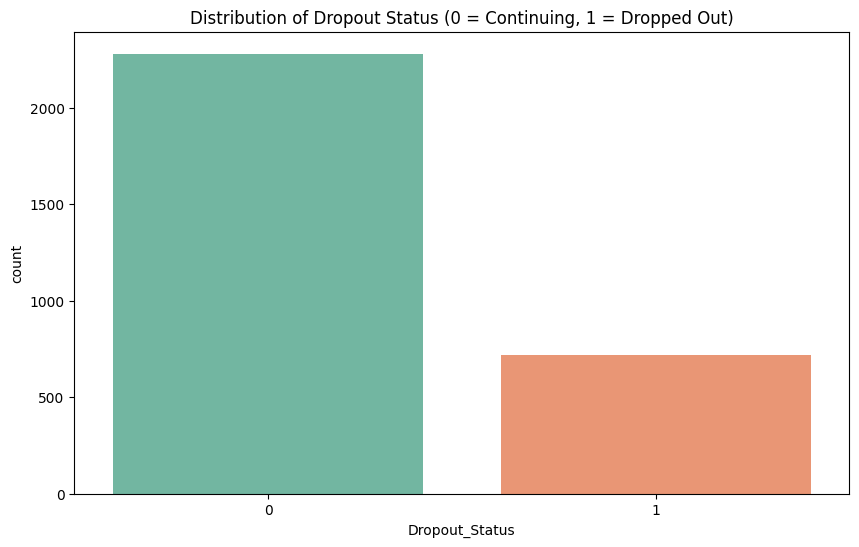

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Dropout_Status', data=df, palette='Set2')
plt.title('Distribution of Dropout Status (0 = Continuing, 1 = Dropped Out)')
plt.savefig('univariate_target.png')


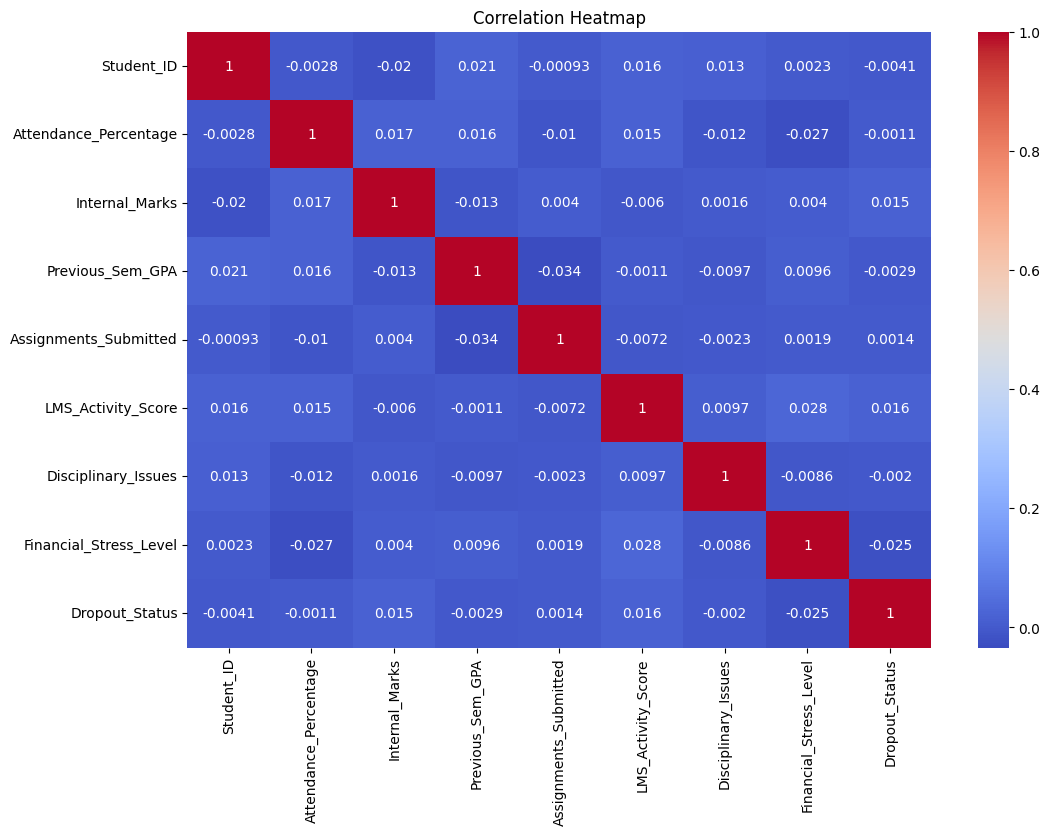

In [ ]:
plt.figure(figsize=(12, 8))
numerical_df = df.select_dtypes(include=[np.number])
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.savefig('multivariate_heatmap.png')

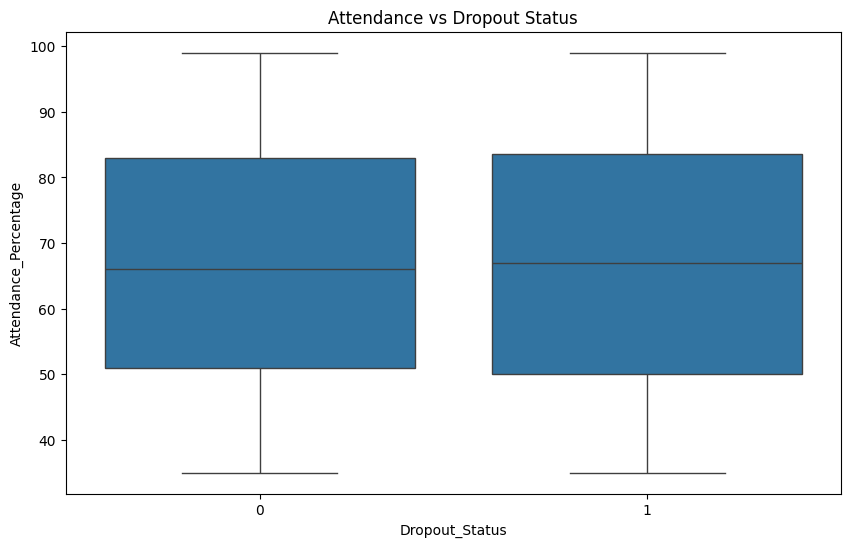

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Dropout_Status', y='Attendance_Percentage', data=df)
plt.title('Attendance vs Dropout Status')
plt.savefig('attendance_boxplot.png')


In [ ]:
df_model = df.drop(['Student_ID', 'Reason_For_Dropout', 'Current_Status'], axis=1)


In [ ]:
le_dict = {}
categorical_cols = ['Family_Issues', 'Family_Income_Level', 'Parent_Occupation', 'Health_Issues']


In [ ]:
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    le_dict[col] = le # Store for UI encoding


In [ ]:
X = df_model.drop('Dropout_Status', axis=1)
y = df_model['Dropout_Status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}")


Model Accuracy: 0.76


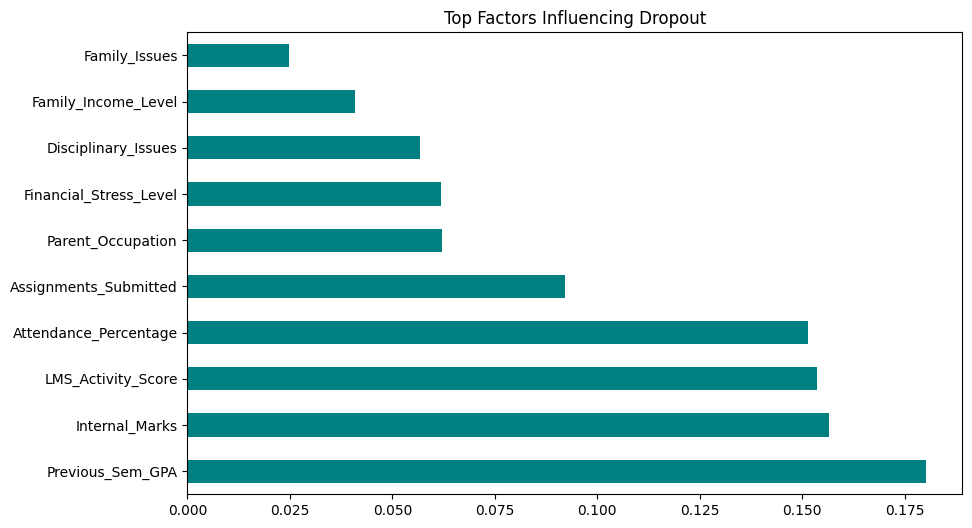

In [ ]:
plt.figure(figsize=(10, 6))
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top Factors Influencing Dropout')
plt.savefig('feature_importance.png')

In [ ]:
def predict_dropout(attendance, internal_marks, gpa, assignments, lms_score, disciplinary,
                    fam_issues, income_level, occupation, health_issues, stress_level):

    # Encode categorical inputs using the stored encoders
    fam_enc = le_dict['Family_Issues'].transform([fam_issues])[0]
    inc_enc = le_dict['Family_Income_Level'].transform([income_level])[0]
    occ_enc = le_dict['Parent_Occupation'].transform([occupation])[0]
    health_enc = le_dict['Health_Issues'].transform([health_issues])[0]

    # Prepare input for model
    features = np.array([[attendance, internal_marks, gpa, assignments, lms_score,
                          disciplinary, fam_enc, inc_enc, occ_enc, health_enc, stress_level]])

    # Prediction
    prob = model.predict_proba(features)[0][1]
    result = "At Risk" if prob > 0.5 else "Safe"

    return f"Prediction: {result}\nDropout Probability: {prob:.2%}"


In [ ]:
interface = gr.Interface(
    fn=predict_dropout,
    inputs=[
        gr.Slider(0, 100, label="Attendance %"),
        gr.Slider(0, 100, label="Internal Marks"),
        gr.Slider(0, 10, label="Previous Sem GPA"),
        gr.Slider(0, 10, step=1, label="Assignments Submitted"),
        gr.Slider(0, 100, label="LMS Activity Score"),
        gr.Dropdown([0, 1, 2, 3], label="Disciplinary Issues Count"),
        gr.Dropdown(["No", "Yes"], label="Family Issues?"),
        gr.Dropdown(["Low", "Medium", "High"], label="Family Income Level"),
        gr.Dropdown(['Business', 'Farmer', 'Government Employee', 'Private Employee', 'Unemployed'], label="Parent Occupation"),
        gr.Dropdown(["No", "Yes"], label="Health Issues?"),
        gr.Slider(1, 5, step=1, label="Financial Stress Level (1-5)")
    ],
    outputs="text",
    title="🎓 Student Dropout Prediction System",
    description="Enter student data to assess the risk of dropping out."
)


In [ ]:
interface.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://1bf617f83951380402.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
